# Workout body heatmap — reconstructed
Loads existing JSON scores and adapted geometry without making API calls. White means zero model contribution; gray regions are context. Both sides share a group score. Cardio/full_body/other remain separate. This restores the latest adapted rendering, not every exploratory cell. Requires NumPy and Matplotlib (install with `%pip install numpy matplotlib` in a separate cell if needed).

In [1]:
from pathlib import Path
import json
import numpy as np
# Start with the original project; change only this line if needed.
project_folder = Path("C:/Users/AndyM/Projects/hevy")
assets_folder = project_folder / "assets"
data_folder = project_folder / "data"
print("Project:", project_folder)

Project: C:\Users\AndyM\Projects\hevy


## Load scores, full reference labels, and body shapes

In [2]:
# Prefer the existing session result. If absent, use the scoring recovery export.
results_path = data_folder / "latest_workout_scores.json"
with results_path.open(encoding="utf-8") as f:
    results = json.load(f)
with (assets_folder / "body_regions_hevy.json").open(encoding="utf-8") as f:
    asset = json.load(f)
with (data_folder / "exercise_templates.json").open(encoding="utf-8") as f:
    templates = json.load(f)
all_groups = set(results["muscle_scores"])
for template in templates.values():
    if template["primary_muscle_group"]:
        all_groups.add(template["primary_muscle_group"])
    all_groups.update(template["secondary_muscle_groups"])
non_anatomical = {"cardio", "full_body", "other"}
body_scores = {m: float(results["muscle_scores"].get(m, 0)) for m in sorted(all_groups - non_anatomical)}
separate_scores = {m: float(results["muscle_scores"].get(m, 0)) for m in sorted(all_groups & non_anatomical)}
regions = asset["muscle_regions"]
mapped = set(regions["front"]) | set(regions["back"])
if set(body_scores) - mapped:
    raise ValueError(f"Missing drawing regions: {set(body_scores) - mapped}")
values = np.array(list(body_scores.values()))
if not np.all(np.isfinite(values)) or np.any(values < 0):
    raise ValueError("Scores must be finite and nonnegative")
print("Loaded:", results_path)
print(results["workout_title"], results["start_time"])
print(json.dumps(body_scores, indent=2))
print("Separate categories:", separate_scores)

Loaded: C:\Users\AndyM\Projects\hevy\data\latest_workout_scores.json
I think upper body focus 2026-11-13T21:39:36+00:00
{
  "abdominals": 0.0,
  "abductors": 0.0,
  "adductors": 0.0,
  "biceps": 8.0,
  "calves": 3.5,
  "chest": 4.0,
  "forearms": 6.0,
  "glutes": 2.0,
  "hamstrings": 9.0,
  "lats": 6.0,
  "lower_back": 0.0,
  "neck": 0.0,
  "quadriceps": 4.0,
  "shoulders": 2.0,
  "traps": 0.0,
  "triceps": 2.0,
  "upper_back": 6.0
}
Separate categories: {'cardio': 1.0, 'full_body': 0.0, 'other': 0.0}


## Draw the heatmap
The normalizer maps scores onto 0–1; the color map turns those positions into colors. All 17 reference anatomical groups must have a region.

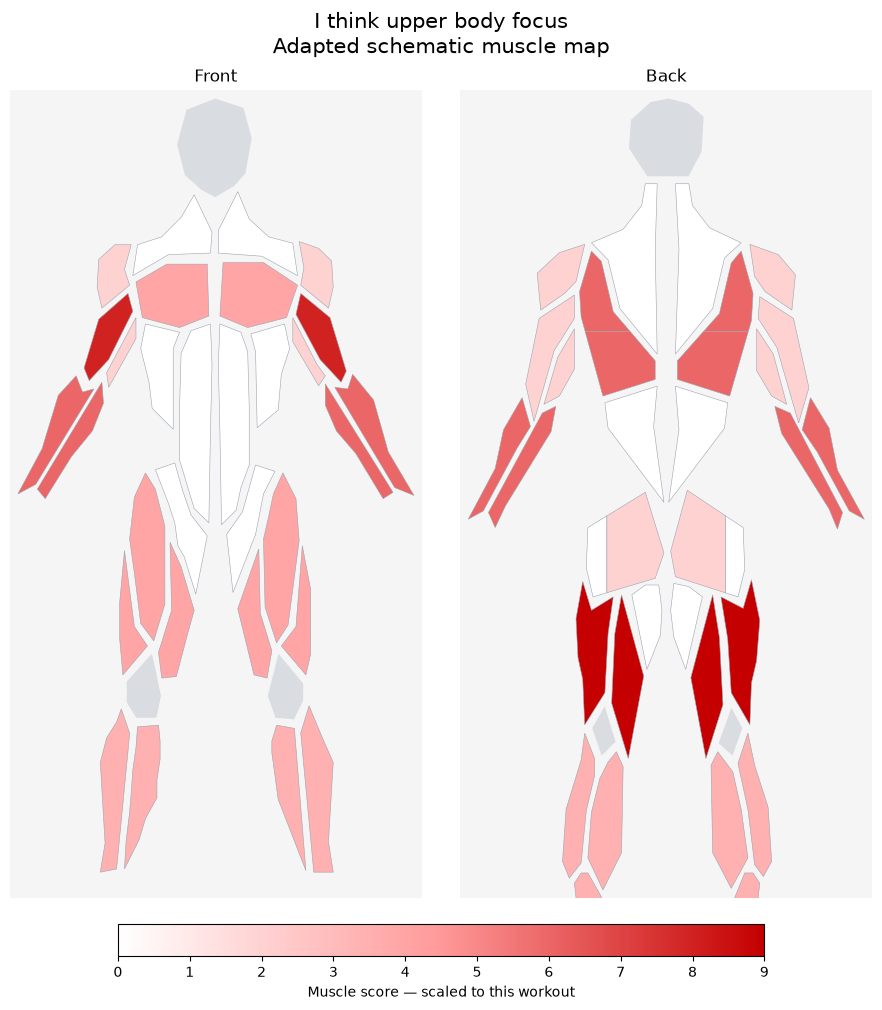

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
color_map = LinearSegmentedColormap.from_list("white_to_red", ["#ffffff", "#ff9999", "#c40000"])
# Set to a number (e.g. 9.0) for a shared scale across comparisons.
scale_max = None
maximum = max(body_scores.values(), default=0.0)
upper = scale_max if scale_max is not None else (maximum if maximum > 0 else 1.0)
if upper <= 0:
    raise ValueError("Scale maximum must be positive")
normalizer = Normalize(vmin=0, vmax=upper, clip=True)
fig, axes = plt.subplots(1, 2, figsize=(9, 10), layout="constrained")
for ax, side in zip(axes, ["front", "back"]):
    ax.set_facecolor("#f5f5f5")
    for shapes in asset["context_regions"][side].values():
        for points in shapes:
            ax.add_patch(Polygon(points, facecolor="#d9dde2", edgecolor="#f5f5f5", linewidth=1))
    for muscle, shapes in regions[side].items():
        for points in shapes:
            ax.add_patch(Polygon(points, facecolor=color_map(normalizer(body_scores.get(muscle, 0))),
                                 edgecolor="#9ca3af", linewidth=0.4))
    ax.set_xlim(-20, 1020)
    ax.set_ylim(2020, -20)
    ax.set_aspect("equal")
    ax.set_title(side.title())
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
label = "Muscle score — " + ("shared scale" if scale_max is not None else "scaled to this workout")
fig.colorbar(ScalarMappable(norm=normalizer, cmap=color_map), ax=list(axes),
             orientation="horizontal", fraction=0.04, pad=0.03, label=label)
fig.suptitle(results["workout_title"] + "\nAdapted schematic muscle map", fontsize=15)
plt.show()

## Optional image export

In [4]:
output_folder = project_folder / "outputs"
output_folder.mkdir(exist_ok=True)
fig.savefig(output_folder / "body_heatmap_recovered.png", dpi=180, bbox_inches="tight")
print("Saved:", output_folder / "body_heatmap_recovered.png")

Saved: C:\Users\AndyM\Projects\hevy\outputs\body_heatmap_recovered.png
